## 0. Configuração do Ambiente e Diretório de Trabalho (Google Drive)

Para garantir a persistência dos arquivos intermediários (`data/processed/`) e dos entregáveis (`outputs/`) entre todos os notebooks do pipeline (`01` a `06`) sem necessidade de reenvio manual a cada sessão do Google Colab, montamos o Google Drive e definimos a pasta raiz do projeto (`ifood-growth-competition-case`) como diretório ativo.

> **Nota de reprodutibilidade:** Caso execute este notebook localmente (VS Code / Jupyter), esta célula identifica automaticamente o ambiente local e mantém o diretório raiz do repositório sem exigir montagem do Google Drive.

In [1]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/ifood-growth-competition-case'
    os.makedirs(PROJECT_DIR, exist_ok=True)
    os.chdir(PROJECT_DIR)
    print("Ambiente Google Colab conectado ao Drive:", os.getcwd())
except ImportError:
    # Execução local (VS Code / Jupyter / Terminal)
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    print("Ambiente local detectado:", os.getcwd())

Mounted at /content/drive
Ambiente Google Colab conectado ao Drive: /content/drive/MyDrive/ifood-growth-competition-case


# 06 — Consolidação dos Entregáveis Executivos

**Objetivo:** Consolidar os resultados da base real **`Case_Competição_prático - Dados.csv`** em um workbook Excel executivo multi-abas (`iFood_Business_Case_Analitico_Real.xlsx`) e gerar o gráfico executivo final.


In [2]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = ".." if os.path.exists("../data/processed/base_alocacao_otimizada.csv") else ("." if os.path.exists("data/processed/base_alocacao_otimizada.csv") else "/content")
OPTIMIZED_PATH = os.path.join(BASE_DIR, "data", "processed", "base_alocacao_otimizada.csv")
SEGMENTED_PATH = os.path.join(BASE_DIR, "data", "processed", "base_segmentada.csv")
SENS_PATH = os.path.join(BASE_DIR, "outputs", "reports", "sensibilidade_cenarios.csv")
EDA_SUMMARY_PATH = os.path.join(BASE_DIR, "outputs", "reports", "eda_summary.json")

EXCEL_DIR = os.path.join(BASE_DIR, "outputs", "excel")
FIGURES_DIR = os.path.join(BASE_DIR, "outputs", "figures")
os.makedirs(EXCEL_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

EXCEL_PATH = os.path.join(EXCEL_DIR, "iFood_Business_Case_Analitico_Real.xlsx")

allocation_df = pd.read_csv(OPTIMIZED_PATH)
segmented_df = pd.read_csv(SEGMENTED_PATH)
sensitivity_df = pd.read_csv(SENS_PATH)

with open(EDA_SUMMARY_PATH, "r", encoding="utf-8") as f:
    eda_kpis = json.load(f)


## 1. Resumo Executivo Consolidado


In [3]:
inv_total = float(allocation_df["investimento_alocado_m"].sum())
gmv_inc = float(allocation_df["gmv_incremental_m"].sum())
mc_inc = float(allocation_df["margem_contribuicao_incremental_m"].sum())
op_inc = float(allocation_df["operating_margin_incremental_m"].sum())

resumo_executivo = pd.DataFrame([
    {"Indicador": "Total de Praças Analisadas", "Valor": eda_kpis["total_cidades"], "Unidade": "Cidades"},
    {"Indicador": "GMV Base Total (12m)", "Valor": eda_kpis["gmv_base_total_m"], "Unidade": "R$ Milhões"},
    {"Indicador": "Pedidos Base Totais (12m)", "Valor": eda_kpis["pedidos_base_total_k"], "Unidade": "Mil Pedidos"},
    {"Indicador": "Margem de Contribuição Base Total", "Valor": eda_kpis["margem_contribuicao_total_m"], "Unidade": "R$ Milhões"},
    {"Indicador": "Operating Margin Base Total", "Valor": eda_kpis["margem_base_total_m"], "Unidade": "R$ Milhões"},
    {"Indicador": "Operating Margin Base Ponderada", "Valor": eda_kpis["margem_base_ponderada_pct"], "Unidade": "%"},
    {"Indicador": "Praças Selecionadas no Portfólio", "Valor": int(len(allocation_df)), "Unidade": "Cidades"},
    {"Indicador": "Investimento Bruto Alocado", "Valor": round(inv_total, 2), "Unidade": "R$ Milhões"},
    {"Indicador": "Pedidos Incrementais Projetados", "Valor": round(float(allocation_df["pedidos_incrementais_k"].sum()), 2), "Unidade": "Mil Pedidos"},
    {"Indicador": "GMV Incremental Projetado", "Valor": round(gmv_inc, 2), "Unidade": "R$ Milhões"},
    {"Indicador": "Margem de Contribuição Incremental", "Valor": round(mc_inc, 2), "Unidade": "R$ Milhões"},
    {"Indicador": "Impacto Líquido na Operating Margin", "Valor": round(op_inc, 2), "Unidade": "R$ Milhões"},
    {"Indicador": "ROI sobre GMV Incremental", "Valor": round(gmv_inc / inv_total, 2) if inv_total > 0 else 0.0, "Unidade": "x"},
])

display(resumo_executivo)


,Indicador,Valor,Unidade
0,Total de Praças Analisadas,20.00,Cidades
1,GMV Base Total (12m),1388.68,R$ Milhões
2,Pedidos Base Totais (12m),17844.02,Mil Pedidos
3,Margem de Contribuição Base Total,110.68,R$ Milhões
4,Operating Margin Base Total,55.36,R$ Milhões
5,Operating Margin Base Ponderada,3.99,%
6,Praças Selecionadas no Portfólio,6.00,Cidades
7,Investimento Bruto Alocado,9.98,R$ Milhões
8,Pedidos Incrementais Projetados,371.11,Mil Pedidos
9,GMV Incremental Projetado,27.52,R$ Milhões


## 2. Exportação do Excel Executivo Multi-Abas


In [4]:
with pd.ExcelWriter(EXCEL_PATH, engine="openpyxl") as writer:
    resumo_executivo.to_excel(writer, sheet_name="Resumo Executivo", index=False)
    allocation_df.to_excel(writer, sheet_name="Alocação Otimizada", index=False)
    segmented_df.to_excel(writer, sheet_name="Base Segmentada", index=False)
    sensitivity_df.to_excel(writer, sheet_name="Sensibilidade", index=False)

print("Excel executivo gerado com sucesso em:", EXCEL_PATH)


Excel executivo gerado com sucesso em: ./outputs/excel/iFood_Business_Case_Analitico_Real.xlsx


## 3. Gráfico Executivo Final


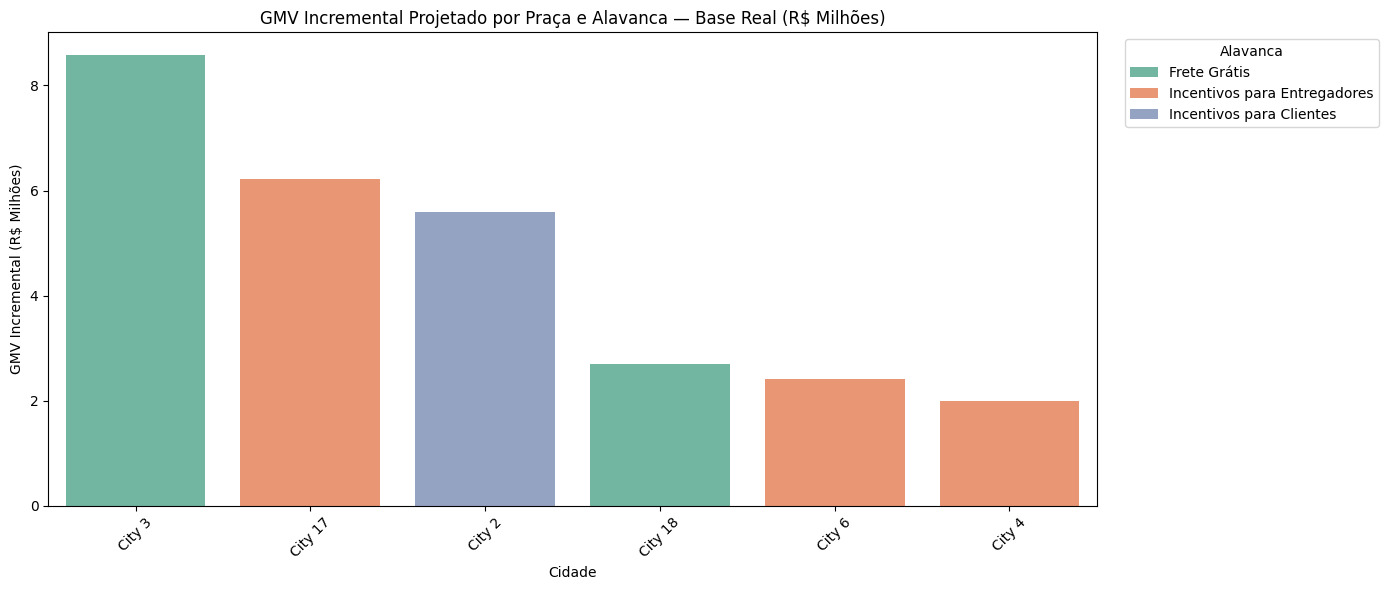

In [5]:
plt.figure(figsize=(14, 6))
sns.barplot(
    data=allocation_df.sort_values("gmv_incremental_m", ascending=False),
    x="cidade",
    y="gmv_incremental_m",
    hue="alavanca",
    palette="Set2"
)
plt.title("GMV Incremental Projetado por Praça e Alavanca — Base Real (R$ Milhões)")
plt.xlabel("Cidade")
plt.ylabel("GMV Incremental (R$ Milhões)")
plt.xticks(rotation=45)
plt.legend(title="Alavanca", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "06_gmv_incremental.png"), bbox_inches="tight", dpi=150)
plt.show()
